In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/features.csv")
X = df.drop(columns=["CONS_NO", "FLAG"])
y = df["FLAG"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Theft rate train:", round(y_train.mean()*100, 2), "%  test:", round(y_test.mean()*100, 2), "%")

Train: (33831, 19)  Test: (8458, 19)
Theft rate train: 8.5 %  test: 8.5 %


In [2]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Linear SVM": make_pipeline(StandardScaler(), LinearSVC()),
    "Random Forest": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=5,
                             eval_metric="logloss", n_jobs=-1, random_state=42),
}

In [3]:
from sklearn.model_selection import StratifiedKFold, cross_validate
import warnings
warnings.filterwarnings("ignore")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
           "f1": "f1", "roc_auc": "roc_auc", "pr_auc": "average_precision"}

results = {}
for name, model in models.items():
    print("Training", name, "...")
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    results[name] = {m: scores[f"test_{m}"].mean() for m in scoring}

baseline = pd.DataFrame(results).T.round(3)
baseline.to_csv("../reports/results_baseline.csv")
baseline

Training Logistic Regression ...
Training Linear SVM ...
Training Random Forest ...
Training XGBoost ...


,accuracy,precision,recall,f1,roc_auc,pr_auc
Logistic Regression,0.915,0.512,0.026,0.050,0.699,0.205
Linear SVM,0.915,0.558,0.019,0.036,0.709,0.217
Random Forest,0.918,0.648,0.090,0.157,0.778,0.323
XGBoost,0.921,0.680,0.133,0.222,0.802,0.379


In [4]:
def evaluate(models_dict):
    rows = {}
    for name, model in models_dict.items():
        print("Training", name, "...")
        s = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
        rows[name] = {m: s[f"test_{m}"].mean() for m in scoring}
    return pd.DataFrame(rows).T.round(3)

In [5]:
ratio = (y_train == 0).sum() / (y_train == 1).sum()
print("Honest : thief ratio =", round(ratio, 1))

weighted_models = {
    "LR (weighted)": make_pipeline(StandardScaler(),
                        LogisticRegression(max_iter=1000, class_weight="balanced")),
    "SVM (weighted)": make_pipeline(StandardScaler(), LinearSVC(class_weight="balanced")),
    "RF (weighted)": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                        class_weight="balanced_subsample", n_jobs=-1, random_state=42),
    "XGB (weighted)": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=5,
                        scale_pos_weight=ratio, eval_metric="logloss",
                        n_jobs=-1, random_state=42),
}
weighted = evaluate(weighted_models)
weighted

Honest : thief ratio = 10.8
Training LR (weighted) ...
Training SVM (weighted) ...
Training RF (weighted) ...
Training XGB (weighted) ...


,accuracy,precision,recall,f1,roc_auc,pr_auc
LR (weighted),0.690,0.157,0.603,0.249,0.715,0.223
SVM (weighted),0.676,0.150,0.603,0.240,0.704,0.207
RF (weighted),0.911,0.455,0.244,0.318,0.783,0.330
XGB (weighted),0.805,0.241,0.605,0.345,0.796,0.360


In [6]:
from imblearn.pipeline import make_pipeline as make_imb_pipeline
from imblearn.over_sampling import SMOTE

smote_models = {
    "LR (SMOTE)": make_imb_pipeline(StandardScaler(), SMOTE(random_state=42),
                                    LogisticRegression(max_iter=1000)),
    "XGB (SMOTE)": make_imb_pipeline(SMOTE(random_state=42),
                        XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=5,
                                      eval_metric="logloss", n_jobs=-1, random_state=42)),
}
smote = evaluate(smote_models)
smote

Training LR (SMOTE) ...
Training XGB (SMOTE) ...


,accuracy,precision,recall,f1,roc_auc,pr_auc
LR (SMOTE),0.688,0.156,0.607,0.249,0.714,0.225
XGB (SMOTE),0.831,0.250,0.494,0.332,0.768,0.322


In [7]:
all_results = pd.concat([baseline, weighted, smote])
all_results.to_csv("../reports/results_all.csv")
all_results.sort_values("pr_auc", ascending=False)

,accuracy,precision,recall,f1,roc_auc,pr_auc
XGBoost,0.921,0.680,0.133,0.222,0.802,0.379
XGB (weighted),0.805,0.241,0.605,0.345,0.796,0.360
RF (weighted),0.911,0.455,0.244,0.318,0.783,0.330
Random Forest,0.918,0.648,0.090,0.157,0.778,0.323
XGB (SMOTE),0.831,0.250,0.494,0.332,0.768,0.322
LR (SMOTE),0.688,0.156,0.607,0.249,0.714,0.225
LR (weighted),0.690,0.157,0.603,0.249,0.715,0.223
Linear SVM,0.915,0.558,0.019,0.036,0.709,0.217
SVM (weighted),0.676,0.150,0.603,0.240,0.704,0.207
Logistic Regression,0.915,0.512,0.026,0.050,0.699,0.205


Best threshold: 0.632
Precision: 0.357  Recall: 0.431  F1: 0.391


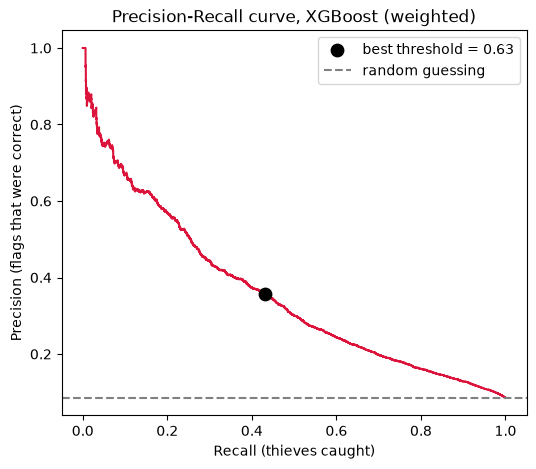

In [8]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

best_model = weighted_models["XGB (weighted)"]
proba = cross_val_predict(best_model, X_train, y_train, cv=cv,
                          method="predict_proba")[:, 1]

precision, recall, thresholds = precision_recall_curve(y_train, proba)
f1 = 2 * precision * recall / (precision + recall + 1e-9)
best_i = f1[:-1].argmax()
best_threshold = thresholds[best_i]

print(f"Best threshold: {best_threshold:.3f}")
print(f"Precision: {precision[best_i]:.3f}  Recall: {recall[best_i]:.3f}  F1: {f1[best_i]:.3f}")

plt.figure(figsize=(6, 5))
plt.plot(recall, precision, color="crimson")
plt.scatter(recall[best_i], precision[best_i], s=80, color="black", zorder=3,
            label=f"best threshold = {best_threshold:.2f}")
plt.axhline(y_train.mean(), linestyle="--", color="gray", label="random guessing")
plt.xlabel("Recall (thieves caught)")
plt.ylabel("Precision (flags that were correct)")
plt.title("Precision-Recall curve, XGBoost (weighted)")
plt.legend()
plt.savefig("../reports/figures/6_pr_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
def tune_threshold(model):
    proba = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    p, r, t = precision_recall_curve(y_train, proba)
    f1 = 2 * p * r / (p + r + 1e-9)
    i = f1[:-1].argmax()
    return {"threshold": t[i], "precision": p[i], "recall": r[i], "f1": f1[i]}

candidates = {
    "XGBoost (plain)": models["XGBoost"],
    "XGB (weighted)": weighted_models["XGB (weighted)"],
}
tuned = {name: tune_threshold(m) for name, m in candidates.items()}
tuned_df = pd.DataFrame(tuned).T.round(3)
print(tuned_df)

winner = tuned_df["f1"].idxmax()
final_model = candidates[winner]
final_threshold = tuned[winner]["threshold"]
print("\nWinner:", winner, " threshold:", round(final_threshold, 3))

                 threshold  precision  recall     f1
XGBoost (plain)      0.187      0.374   0.420  0.396
XGB (weighted)       0.632      0.357   0.431  0.391

Winner: XGBoost (plain)  threshold: 0.187


              precision    recall  f1-score   support

      Honest      0.945     0.940     0.943      7739
       Thief      0.393     0.416     0.404       719

    accuracy                          0.896      8458
   macro avg      0.669     0.678     0.673      8458
weighted avg      0.898     0.896     0.897      8458

ROC-AUC: 0.803
PR-AUC : 0.391

Top 422 most suspicious customers: 51.9% are real thieves


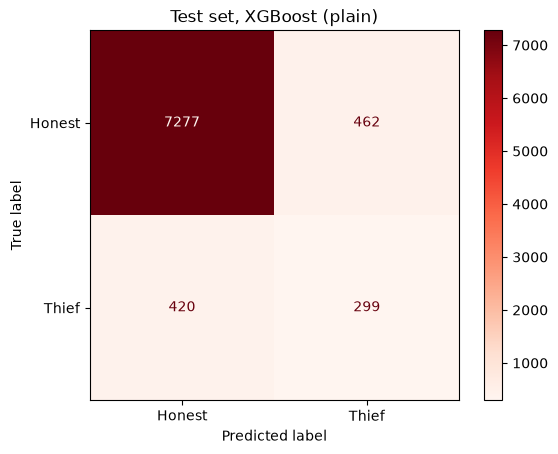

In [10]:
from sklearn.metrics import (classification_report, roc_auc_score,
                             average_precision_score, ConfusionMatrixDisplay)

final_model.fit(X_train, y_train)                 # train on ALL training data
test_proba = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= final_threshold).astype(int)

print(classification_report(y_test, test_pred, target_names=["Honest", "Thief"], digits=3))
print("ROC-AUC:", round(roc_auc_score(y_test, test_proba), 3))
print("PR-AUC :", round(average_precision_score(y_test, test_proba), 3))

# Inspector view: if they can only visit the top 5% most suspicious customers
k = int(0.05 * len(y_test))
top_k = np.argsort(test_proba)[::-1][:k]
print(f"\nTop {k} most suspicious customers: {y_test.iloc[top_k].mean()*100:.1f}% are real thieves")

ConfusionMatrixDisplay.from_predictions(y_test, test_pred,
        display_labels=["Honest", "Thief"], cmap="Reds")
plt.title(f"Test set, {winner}")
plt.savefig("../reports/figures/7_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
import joblib
joblib.dump({"model": final_model,
             "threshold": final_threshold,
             "features": list(X.columns)},
            "../models/theft_model.joblib")
print("Model saved!")

Model saved!
